# Tokenization Lab — IMDb Reviews

Notebook này khảo sát dữ liệu review phim, cách BERT tokenizer tạo subword, ảnh hưởng của độ dài tối đa, truncation và padding. Các biểu đồ được hiển thị trực tiếp trong notebook. Seed cố định: **2026**.

> Hãy tự ghi dự đoán trước khi chạy mỗi thực nghiệm, sau đó tự giải thích kết quả/biểu đồ theo yêu cầu của bài lab.

In [1]:
from pathlib import Path
from zipfile import ZipFile
import re, random, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from IPython.display import display, Markdown
from transformers import AutoTokenizer

SEED = 2026
MODEL_NAME = 'prajjwal1/bert-tiny'
MAX_LENGTHS = [32, 64, 128, 256, 512]
random.seed(SEED); np.random.seed(SEED)
sns.set_theme(style='whitegrid', context='notebook')
plt.rcParams['figure.figsize'] = (9, 5)

# archive.zip is expected in the sibling data folder.
DATA_ZIP = Path('../data/archive.zip')
if not DATA_ZIP.exists():
    # Also support running the notebook with the lab folder as the current directory.
    candidates = [Path.cwd() / '../data/archive.zip', Path.cwd() / 'data/archive.zip']
    DATA_ZIP = next((p.resolve() for p in candidates if p.exists()), DATA_ZIP)
if not DATA_ZIP.exists():
    raise FileNotFoundError(f'Không tìm thấy {DATA_ZIP.resolve()}. Hãy đặt archive.zip trong thư mục data cạnh lab08.')

def load_imdb_zip(zip_path):
    """Read either the common Kaggle CSV or the aclImdb directory layout."""
    with ZipFile(zip_path) as zf:
        names = zf.namelist()
        csv_names = [n for n in names if n.lower().endswith('.csv') and not n.endswith('/')]
        # Prefer the standard Kaggle IMDb review CSV.
        preferred = [n for n in csv_names if 'imdb' in n.lower() or 'review' in n.lower()]
        for member in preferred + [n for n in csv_names if n not in preferred]:
            try:
                frame = pd.read_csv(zf.open(member))
                cols = {c.lower().strip(): c for c in frame.columns}
                text_col = next((cols[k] for k in ('review', 'text', 'content') if k in cols), None)
                label_col = next((cols[k] for k in ('sentiment', 'label', 'polarity') if k in cols), None)
                if text_col and label_col:
                    out = frame[[text_col, label_col]].rename(columns={text_col: 'text', label_col: 'label'})
                    return out, f'CSV: {member}'
            except Exception:
                continue
        # Support aclImdb/{train,test}/{pos,neg}/*.txt archives.
        rows = []
        for member in names:
            match = re.search(r'aclImdb/(?:train|test)/(pos|neg)/[^/]+\.txt$', member, re.I)
            if match:
                rows.append((zf.read(member).decode('utf-8', errors='replace'), match.group(1).lower()))
        if rows:
            return pd.DataFrame(rows, columns=['text', 'label']), 'aclImdb text files'
    raise ValueError('Không tìm thấy CSV có cột review/sentiment hoặc thư mục aclImdb/{pos,neg} trong ZIP.')

raw_df, data_format = load_imdb_zip(DATA_ZIP)
raw_df = raw_df.dropna(subset=['text', 'label']).copy()
raw_df['text'] = raw_df['text'].astype(str).str.strip()
raw_df = raw_df[raw_df['text'].str.len() > 0].drop_duplicates(subset='text').reset_index(drop=True)
def encode_label(value):
    value = str(value).strip().lower()
    if value in {'positive', 'pos', '1', '1.0'}: return 1
    if value in {'negative', 'neg', '0', '0.0'}: return 0
    try: return int(float(value) > 0)
    except ValueError: raise ValueError(f'Nhãn không nhận diện được: {value!r}')
raw_df['label'] = raw_df['label'].map(encode_label).astype(int)
# Stratified 60/20/20 split: train, validation, test.
train_df, holdout_df = train_test_split(raw_df, test_size=0.4, random_state=SEED, stratify=raw_df['label'])
valid_df, test_df = train_test_split(holdout_df, test_size=0.5, random_state=SEED, stratify=holdout_df['label'])
train_df = train_df.reset_index(drop=True); valid_df = valid_df.reset_index(drop=True); test_df = test_df.reset_index(drop=True)
splits = {'train': train_df, 'validation': valid_df, 'test': test_df}
print(f'Data: {DATA_ZIP.resolve()} | format: {data_format} | N={len(raw_df):,}')
display(pd.DataFrame([{'split': name, 'rows': len(frame), 'fraction': len(frame)/len(raw_df), 'positive_rate': frame.label.mean()} for name, frame in splits.items()]))

C:\Users\User\AppData\Local\Programs\Python\Python310\lib\site-packages\requests\__init__.py:113: RequestsDependencyWarning: urllib3 (2.6.2) or chardet (7.4.3)/charset_normalizer (3.4.4) doesn't match a supported version!
  warnings.warn(


Data: D:\Study\Study_Class\Semester_7\NLP\Lab\data\archive.zip | format: CSV: IMDB Dataset.csv | N=49,582


,split,rows,fraction,positive_rate
0,train,29749,0.599996,0.501866
1,validation,9916,0.199992,0.501916
2,test,9917,0.200012,0.501865


<!-- codex-analysis-tok-data -->
### Nhận xét về split dữ liệu

ZIP chứa `IMDB Dataset.csv`; sau khi bỏ dòng trống và review trùng còn 49.582 mẫu. Split stratified cho 29.749 train (60%), 9.916 validation (20%) và 9.917 test (20%). Tỷ lệ positive ở cả ba split đều xấp xỉ 0,5019, nên phân bố nhãn được giữ ổn định và gần cân bằng. Đây là split của toàn bộ dữ liệu IMDb, khác với các subset tối đa 2.400/800/800 dùng để huấn luyện nhanh trong notebook fine-tuning.


## 1. Dataset overview

**Dự đoán trước khi chạy:** lớp nào nhiều hơn? Review dài/ngắn có khác nhau giữa hai nhãn không? Viết dự đoán và giải thích sau khi xem biểu đồ.

C:\Users\User\AppData\Local\Temp\ipykernel_30360\1829153055.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=raw_df, x='label_name', order=['Negative','Positive'], ax=axes[0], palette='Set2')
C:\Users\User\AppData\Local\Temp\ipykernel_30360\1829153055.py:9: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=raw_df, x='label_name', y='char_count', order=['Negative','Positive'], showfliers=False, ax=axes[2], palette='Set3')


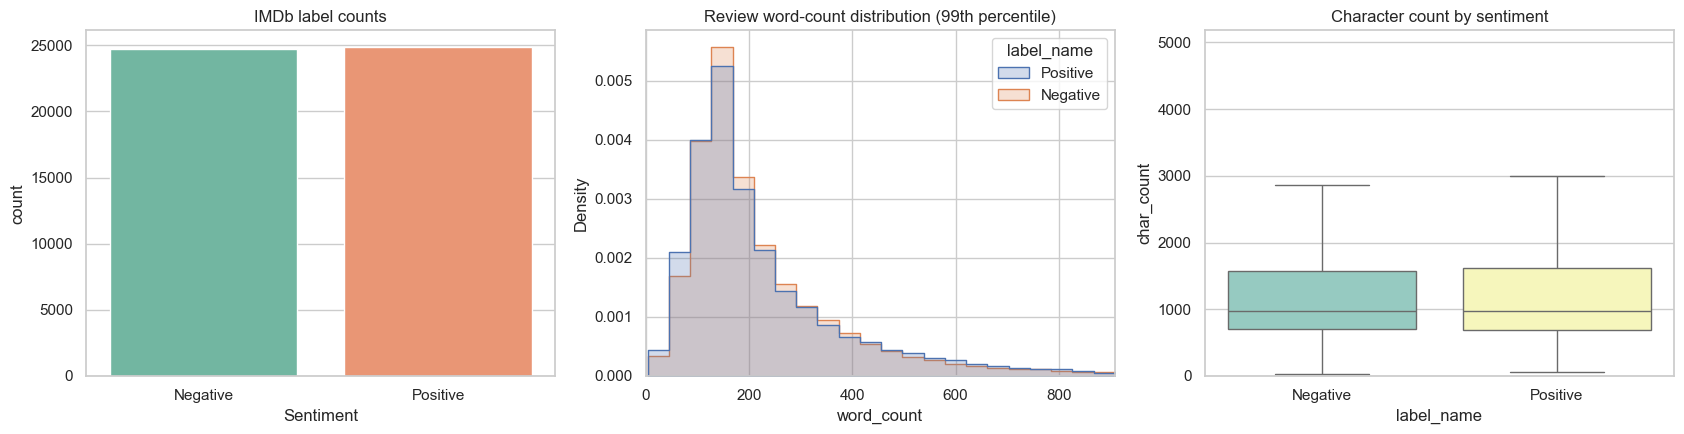

word_count                                                   \
                count   mean    std   min    25%    50%    75%     max   
label_name                                                               
Negative      24698.0  229.6  165.1   4.0  128.0  174.0  278.0  1522.0   
Positive      24884.0  233.1  177.7  10.0  125.0  172.0  284.0  2470.0   

           char_count                                                       
                count    mean     std   min    25%    50%     75%      max  
label_name                                                                  
Negative      24698.0  1294.7   946.5  32.0  706.0  974.0  1568.0   8969.0  
Positive      24884.0  1326.3  1032.6  65.0  692.0  969.0  1615.2  13704.0

,label_name,word_count,text
15570,Positive,135,"I saw this film in the worst possible circumstance. I'd already missed 15 minutes when I woke up to it on an international flight between Sydney and Seoul. I didn't know what I was watching, I thought maybe it was a movie of the week, but quickly became riveted by the performance of the lead actress playing a young woman who's child had been kidnapped. The premise started taking twist and turns I didn't see coming and by the end credits I was scrambling through the the in-flight guide to figure out what I had just watched. Turns out I was belatedly discovering Do-yeon Jeon who'd won Best Actress at Cannes for the role. I don't know if Secret Sunshine is typical of Korean cinema but I'm off to the DVD store to discover more."
46679,Positive,382,"This movie was beautiful and touching. It touched a place deep inside me and I'm not sure why. I am a happily married woman and I've never had lesbian tendencies, but my, this movie almost made it something I crave. The choreography, the storyline, the dialog... the movie was a work of art. The synopsis without spoilers is that a woman gymnast unsatisfied with her life and looking for... something, anything. She is with a man who does not want a baby, but she does. He's not mean to her, but he doesn't treat her the way a woman should be treated either... I guess he doesn't really appreciate her. All these years she has stayed in shape and decides to go back to the gym. She meets another woman during her acrobatic training and an intimate and beautiful relationship unfolds. Throughout the movie she has another woman friend that she trained with in her younger years, and they have stayed close friends.The relationship that unfolds is.. I don't know quite the word, but very understanding, comfortable, intimate but sexy... something that could only exist between two women. The kind of relationship that could really bring meaning back into your life. Someone that makes you feel special, exciting, beautiful, confused even.The relationship with her close friend is beautiful in an equally different way. They have a close and intimate relationship. Her friend showed me what a true friend really is. Someone who is understanding, easy going, REAL, fun to be with, someone who is there for you no matter what. Someone who is supportive, and you can huddle with and tell your deepest secrets. Someone who shares your past but does not share your secrets. The story is simple in the fact that it was not overdone, but not underdone in any way. It leaves a lot of sensual imagery to capture it's moments. The dancing and choreography was stunning. I could watch it over and over. The way the artist captured the main character's feelings and emotions was. The dancing and the imagery was very dazzling and mesmerizing to watch. What a cozy a wonderful story! I fell in love with this movie. If you have a chance, rent this and watch it!!"
21988,Negative,177,"I was really geared up to watch when two of best movie critics tagged this movie as a 'laugh riot'. But the movie turned out be disappointing.You will be advised to watch this movie keeping your brains at home but you simply can't ignore the flaws and the shortcomings.1. The missile scene was total stupidity.2. Katrina Kaif and Govinda pair looked awful. (He's 49 and she's just 24... more than double of her age) 3. Salman's comedy is less of acting and more of overacting.4. Songs are good but interrupts the pace of the movie.5. Some scenes were deliberately attempted by the movie makers to be funny, and 6. Poor and flawed story.However, there are few pluses- 1. Govinda. Great Individual Performance.2. Some scenes are actually quite funny.3. Kattrina Kaif. Looks and Acting keeps on improving with every film.4. Rajpal Yadav's Don sequences. Though under-utilized but hilarious.So 4 good points, 6 bad ones.. this one gets 4/10."
40574,Negative,128,"With an absolutely amazing cast and crew, this might have been a class

In [2]:
raw_df['word_count'] = raw_df.text.str.split().str.len()
raw_df['char_count'] = raw_df.text.str.len()
raw_df['label_name'] = raw_df.label.map({0: 'Negative', 1: 'Positive'})
fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))
sns.countplot(data=raw_df, x='label_name', order=['Negative','Positive'], ax=axes[0], palette='Set2')
axes[0].set_title('IMDb label counts'); axes[0].set_xlabel('Sentiment')
sns.histplot(data=raw_df, x='word_count', hue='label_name', bins=60, stat='density', common_norm=False, element='step', ax=axes[1])
axes[1].set_xlim(0, raw_df.word_count.quantile(.99)); axes[1].set_title('Review word-count distribution (99th percentile)')
sns.boxplot(data=raw_df, x='label_name', y='char_count', order=['Negative','Positive'], showfliers=False, ax=axes[2], palette='Set3')
axes[2].set_title('Character count by sentiment'); axes[2].set_ylim(0, raw_df.char_count.quantile(.99))
plt.tight_layout(); plt.show()
display(raw_df.groupby('label_name')[['word_count','char_count']].describe().round(1))
display(raw_df.sample(min(5, len(raw_df)), random_state=SEED)[['label_name','word_count','text']].style.set_properties(subset=['text'], **{'max-width':'600px','white-space':'pre-wrap'}))

<!-- codex-analysis-tok-stats -->
### Nhận xét về phân bố review

Có 24.698 review negative và 24.884 positive, chỉ lệch 186 mẫu trên 49.582 review. Số từ trung bình là 229,6 ở negative và 233,1 ở positive; median lần lượt 174 và 172, nên hai lớp khá gần nhau về độ dài điển hình. Tuy nhiên đuôi dài khác nhau: review positive dài nhất 2.470 từ, negative dài nhất 1.522 từ. Chỉ từ thống kê này chưa thấy chênh lệch lớn giữa hai lớp ở median, nhưng có một số review rất dài có thể bị cắt khi đặt giới hạn token.


## 2. Load tokenizer and inspect one review

Tokenizer ưu tiên cache cục bộ trước; nếu chưa có cache thì tải `prajjwal1/bert-tiny`. Tokenizer tạo `[CLS]`, `[SEP]` và subword tokens. Hãy tự mô tả vai trò của chúng.

Loaded tokenizer from local Hugging Face cache.
Label: 0 | chars: 725 | whitespace words: 122 | subwords incl. specials: 168


C:\Users\User\AppData\Local\Programs\Python\Python310\lib\site-packages\transformers\tokenization_utils_base.py:1601: FutureWarning: `clean_up_tokenization_spaces` was not set. It will be set to `True` by default. This behavior will be depracted in transformers v4.45, and will be then set to `False` by default. For more details check this issue: https://github.com/huggingface/transformers/issues/31884
  warnings.warn(


,position,token,token_id,attention_mask,special_token
0,0,[CLS],101,1,1
1,1,for,2005,1,0
2,2,sci,16596,1,0
3,3,-,1011,1,0
4,4,fans,4599,1,0
...,...,...,...,...,...
75,75,good,2204,1,0
76,76,science,2671,1,0
77,77,but,2021,1,0
78,78,it,2009,1,0


Special tokens: {'unk_token': '[UNK]', 'sep_token': '[SEP]', 'pad_token': '[PAD]', 'cls_token': '[CLS]', 'mask_token': '[MASK]'}
Decoded first 80: [CLS] for sci - fans this will be better than anything likely to be running on tv at any given time ; that's about the best you can say of it. good points ; repartee and sense of humour is less dull than usual in such movies, the plot is coherent and doesn't use any magical mystical revelations. bad points ; the writers try to do good science but it falls


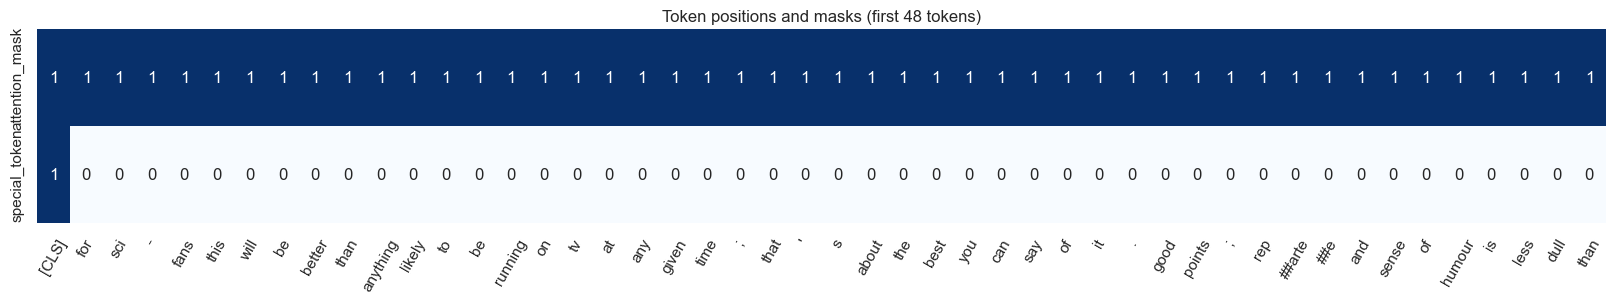

In [3]:
try:
    tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME, local_files_only=True)
    print('Loaded tokenizer from local Hugging Face cache.')
except Exception:
    print('Tokenizer not cached; downloading from Hugging Face...')
    tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)

example = train_df.iloc[0].text
enc = tokenizer(example, add_special_tokens=True, truncation=False, return_special_tokens_mask=True)
tokens = tokenizer.convert_ids_to_tokens(enc['input_ids'])
print('Label:', train_df.iloc[0].label, '| chars:', len(example), '| whitespace words:', len(example.split()), '| subwords incl. specials:', len(tokens))
display(pd.DataFrame({'position': range(min(len(tokens), 80)), 'token': tokens[:80], 'token_id': enc['input_ids'][:80], 'attention_mask': enc['attention_mask'][:80], 'special_token': enc['special_tokens_mask'][:80]}))
print('Special tokens:', tokenizer.special_tokens_map)
print('Decoded first 80:', tokenizer.decode(enc['input_ids'][:80], skip_special_tokens=False))
# Visualize token and mask positions for an initial span.
n = min(48, len(tokens))
fig, ax = plt.subplots(figsize=(max(12, n*.34), 3.2))
mask_view = np.array([enc['attention_mask'][:n], enc['special_tokens_mask'][:n]])
sns.heatmap(mask_view, cmap='Blues', vmin=0, vmax=1, annot=True, fmt='d', cbar=False, xticklabels=tokens[:n], yticklabels=['attention_mask','special_token'], ax=ax)
ax.set_title('Token positions and masks (first 48 tokens)'); ax.tick_params(axis='x', rotation=60)
plt.tight_layout(); plt.show()

<!-- codex-analysis-tok-example -->
### Nhận xét về ví dụ tokenization

Review được chọn có nhãn 0 (negative), 122 từ theo khoảng trắng và 168 token gồm special tokens. Bảng cho thấy `[CLS]` ở vị trí đầu có ID 101, attention mask bằng 1 và special-token mask bằng 1; các từ nội dung có attention mask bằng 1 nhưng special-token mask bằng 0. Tokenizer khai báo `[CLS]`, `[SEP]`, `[PAD]`, `[MASK]` và `[UNK]`; chuỗi đầu vào có thêm token phân cách `[SEP]` ở cuối. Bảng chỉ in 80 vị trí đầu, nên không phải toàn bộ 168 token của review.


## 3. Experiment — word tokens vs BERT subwords

Đo trên mẫu ngẫu nhiên cố định từ train để thời gian chạy hợp lý. Token count gồm special tokens; có thêm cột tách riêng phần overhead của special tokens.

Analyzed 5,000 reviews; special tokens per single sequence: 2


,word_count,subword_count,subword_with_specials,subwords_per_word
count,5000.00,5000.00,5000.00,5000.00
mean,231.34,308.77,310.77,1.33
std,174.10,234.95,234.95,0.12
min,11.00,19.00,21.00,1.04
50%,172.00,228.00,230.00,1.32
90%,446.10,609.00,611.00,1.48
95%,580.00,782.25,784.25,1.55
99%,923.01,1218.01,1220.01,1.69
max,2470.00,3125.00,3127.00,2.09


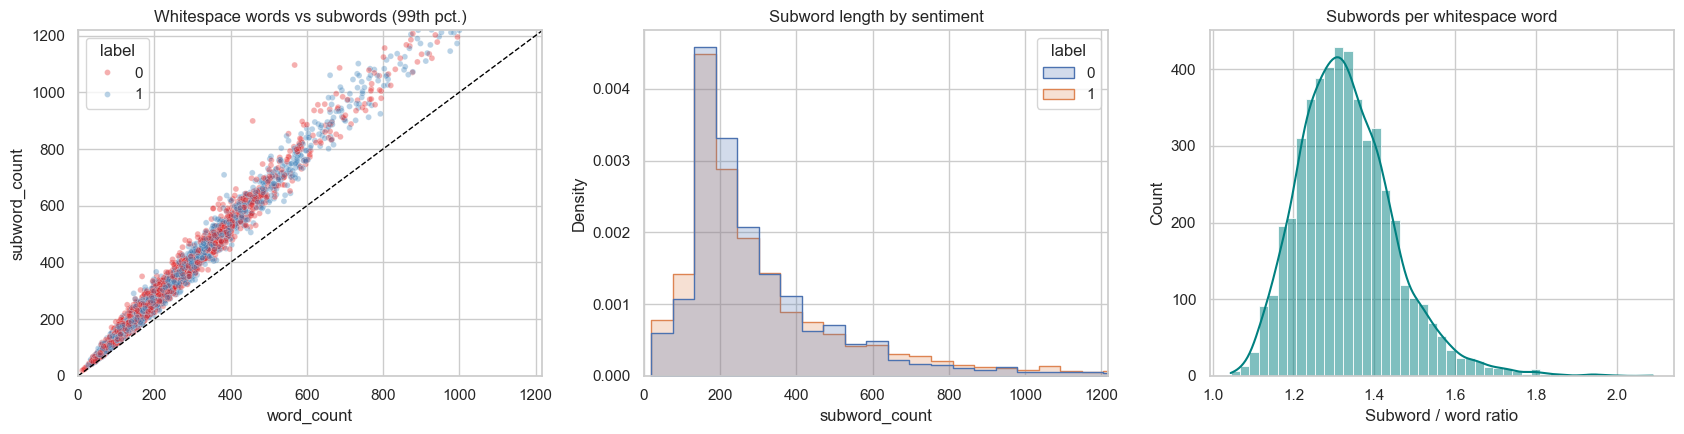

Pearson correlation: 0.993


In [4]:
ANALYSIS_N = min(5000, len(train_df))
tok_sample = train_df.sample(ANALYSIS_N, random_state=SEED).reset_index(drop=True).copy()
tok_sample['word_count'] = tok_sample.text.str.split().str.len()
tok_sample['char_count'] = tok_sample.text.str.len()
tok_sample['subword_count'] = [len(tokenizer(text, add_special_tokens=False, truncation=False)['input_ids']) for text in tok_sample.text]
tok_sample['subword_with_specials'] = tok_sample.subword_count + tokenizer.num_special_tokens_to_add(pair=False)
tok_sample['subwords_per_word'] = tok_sample.subword_count / tok_sample.word_count.clip(lower=1)
print(f'Analyzed {len(tok_sample):,} reviews; special tokens per single sequence: {tokenizer.num_special_tokens_to_add(pair=False)}')
display(tok_sample[['word_count','subword_count','subword_with_specials','subwords_per_word']].describe(percentiles=[.5,.9,.95,.99]).round(2))
fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))
sns.scatterplot(data=tok_sample, x='word_count', y='subword_count', hue='label', alpha=.35, s=18, ax=axes[0], palette='Set1', legend='full')
lim = max(tok_sample.word_count.quantile(.99), tok_sample.subword_count.quantile(.99)); axes[0].plot([0,lim],[0,lim], '--', color='black', linewidth=1)
axes[0].set_xlim(0,lim); axes[0].set_ylim(0,lim); axes[0].set_title('Whitespace words vs subwords (99th pct.)')
sns.histplot(data=tok_sample, x='subword_count', hue='label', bins=55, element='step', stat='density', common_norm=False, ax=axes[1])
axes[1].set_xlim(0, tok_sample.subword_count.quantile(.99)); axes[1].set_title('Subword length by sentiment')
sns.histplot(tok_sample.subwords_per_word, bins=45, kde=True, ax=axes[2], color='teal')
axes[2].set_title('Subwords per whitespace word'); axes[2].set_xlabel('Subword / word ratio')
plt.tight_layout(); plt.show()
print('Pearson correlation:', round(tok_sample[['word_count','subword_count']].corr().iloc[0,1], 4))

<!-- codex-analysis-tok-subwords -->
### Trả lời so sánh từ và subword

Trên 5.000 review lấy mẫu cố định, trung bình có 231,34 từ khoảng trắng nhưng 308,77 subword nội dung; cộng hai special token thành 310,77 token mỗi review. Tỷ lệ trung bình là 1,33 subword/từ, median 1,32 và p95 là 1,55. Tương quan Pearson giữa số từ và số subword cao, 0,993, nghĩa là review nhiều từ thường cũng có nhiều subword; hai phép đếm vẫn không bằng nhau do từ hiếm, hình thái, dấu câu và cách tokenizer chia từ thành mảnh. Mẫu dài nhất có 2.470 từ và 3.125 subword nội dung.


## 4. Experiment — truncation at different maximum lengths

Mỗi review được mã hóa không truncation một lần; sau đó thống kê tỷ lệ review vượt từng ngưỡng 32/64/128/256/512 và tỷ lệ subword còn được giữ lại. Dự đoán trước: max length tăng sẽ tác động thế nào đến truncation và chi phí tính toán?

,max_length,truncated_reviews_pct,mean_tokens_kept_pct,mean_tokens_kept
0,32,99.92,15.54,31.99
1,64,98.34,30.69,63.82
2,128,89.68,56.06,123.75
3,256,43.80,83.43,207.38
4,512,14.40,95.97,273.32


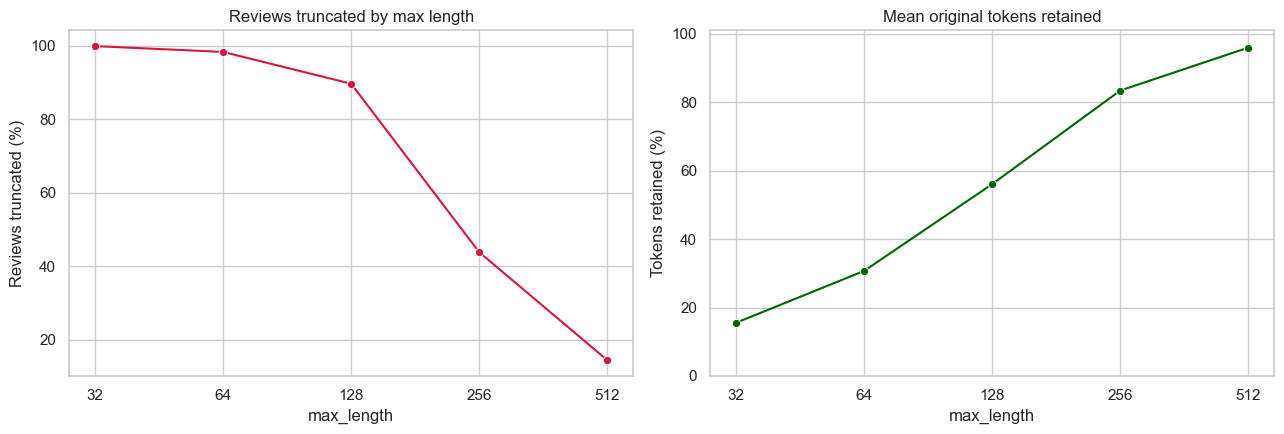


Review #843: original=3127 tokens, kept@128=128
Original tail: , but this one was a winner. i give this ppv a a - < br / > < br / > [SEP]
Truncated tail: , but the referee restrained him while benoit and guerrero ganged up on him in the corner. with benoit stomping [SEP]

Review #1510: original=2293 tokens, kept@128=128
Original tail: they absolutely needed. < br / > < br / > * * * 1 / 2 out of * * * * [SEP]
Truncated tail: , and a prevading sense of dread and claustrophobia that effectively consumes the narrarive with a [SEP]

Review #4551: original=2166 tokens, kept@128=128
Original tail: 4 out of 10 - - the movie is enjoyable but as i think about the plot, it seeps ever lower. [SEP]
Truncated tail: worse films in that motif. the characters are weak. even the background that each member trots out seems stock and awkward [SEP]


In [5]:
lengths = tok_sample.subword_with_specials.to_numpy()
trunc_rows = []
for max_len in MAX_LENGTHS:
    trunc_rows.append({'max_length': max_len, 'truncated_reviews_pct': 100*np.mean(lengths > max_len), 'mean_tokens_kept_pct': 100*np.mean(np.minimum(lengths,max_len)/np.maximum(lengths,1)), 'mean_tokens_kept': np.mean(np.minimum(lengths,max_len))})
trunc_df = pd.DataFrame(trunc_rows)
display(trunc_df.round(2))
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
sns.lineplot(data=trunc_df, x='max_length', y='truncated_reviews_pct', marker='o', ax=axes[0], color='crimson')
axes[0].set_xscale('log', base=2); axes[0].set_xticks(MAX_LENGTHS, labels=MAX_LENGTHS); axes[0].set_title('Reviews truncated by max length'); axes[0].set_ylabel('Reviews truncated (%)')
sns.lineplot(data=trunc_df, x='max_length', y='mean_tokens_kept_pct', marker='o', ax=axes[1], color='darkgreen')
axes[1].set_xscale('log', base=2); axes[1].set_xticks(MAX_LENGTHS, labels=MAX_LENGTHS); axes[1].set_ylim(0,101); axes[1].set_title('Mean original tokens retained'); axes[1].set_ylabel('Tokens retained (%)')
plt.tight_layout(); plt.show()
# Inspect longest reviews and the visible tail after truncation.
longest_idx = np.argsort(lengths)[-3:][::-1]
for idx in longest_idx:
    text = tok_sample.iloc[idx].text
    full_ids = tokenizer(text, add_special_tokens=True, truncation=False)['input_ids']
    cut = tokenizer(text, add_special_tokens=True, truncation=True, max_length=128)['input_ids']
    print(f'\nReview #{idx}: original={len(full_ids)} tokens, kept@128={len(cut)}')
    print('Original tail:', tokenizer.decode(full_ids[-25:], skip_special_tokens=False))
    print('Truncated tail:', tokenizer.decode(cut[-25:], skip_special_tokens=False))

<!-- codex-analysis-tok-truncation -->
### Trả lời về truncation và max length

Truncation giảm khi tăng giới hạn, nhưng vẫn ảnh hưởng phần lớn review ở các ngưỡng ngắn: 99,92% review vượt 32 token, 98,34% vượt 64 và 89,68% vượt 128. Ở 256, tỷ lệ còn 43,80%; ở 512 còn 14,40%. Trung bình token gốc được giữ lần lượt 15,54%, 30,69%, 56,06%, 83,43% và 95,97% tại các giới hạn 32, 64, 128, 256, 512. Do đó max_length=128 cắt bỏ nhiều nội dung IMDb; 256 là thỏa hiệp tốt hơn trong số liệu này, còn 512 giữ nhiều ngữ cảnh hơn nhưng tốn tính toán hơn. Đây là thống kê độ dài, chưa tự nó chứng minh chất lượng phân loại tăng; xem thêm kết quả Experiment 4 trong notebook fine-tuning.

Các ví dụ dài nhất có 2.166–3.127 token, nhưng khi giới hạn 128 chỉ giữ 128 token đầu và phần cuối gốc không còn trong đầu vào. Điều này giải thích cụ thể vì sao nhận xét ở cuối review có thể bị mất khi dùng giới hạn ngắn.


## 5. Experiment — subword fragmentation

Xem từ thường gặp mà tokenizer tách thành nhiều mảnh, cùng ví dụ phân đoạn thực tế. Đây là phép đo trực tiếp từ vocabulary/tokenizer, không phải đánh giá chất lượng mô hình.

,word,frequency,pieces,segmentation
0,it's,3257,3,it | ' | s
1,don't,1685,3,don | ' | t
2,doesn't,923,3,doesn | ' | t
3,i'm,896,3,i | ' | m
4,didn't,857,3,didn | ' | t
5,i've,690,3,i | ' | ve
6,can't,689,3,can | ' | t
7,that's,667,3,that | ' | s
8,isn't,604,3,isn | ' | t
9,there's,573,3,there | ' | s


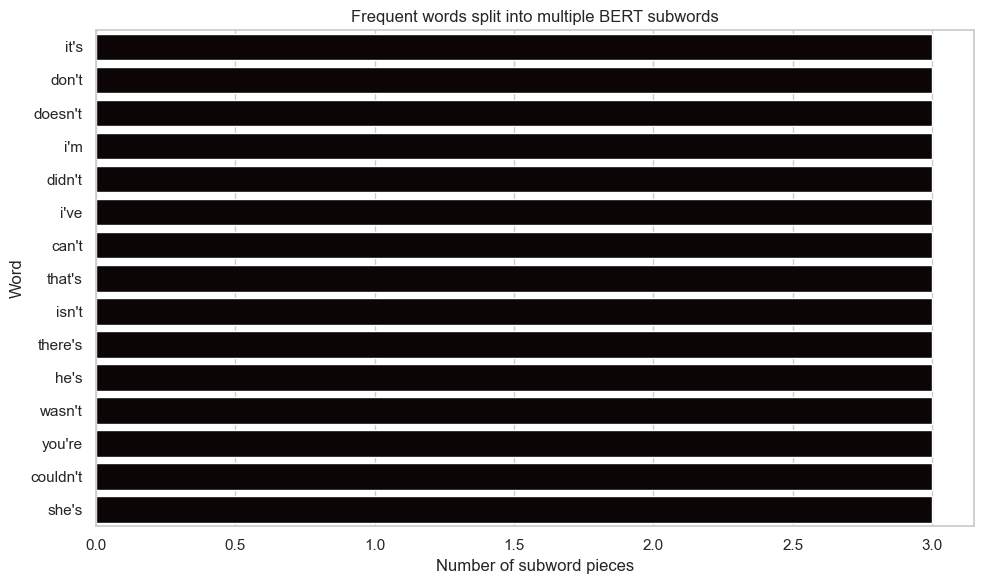

C:\Users\User\AppData\Local\Temp\ipykernel_30360\3762686787.py:20: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  plt.figure(figsize=(8,4.5)); sns.violinplot(data=tok_sample, x='label', y='subwords_per_word', inner='quartile', cut=0, palette='Set2')


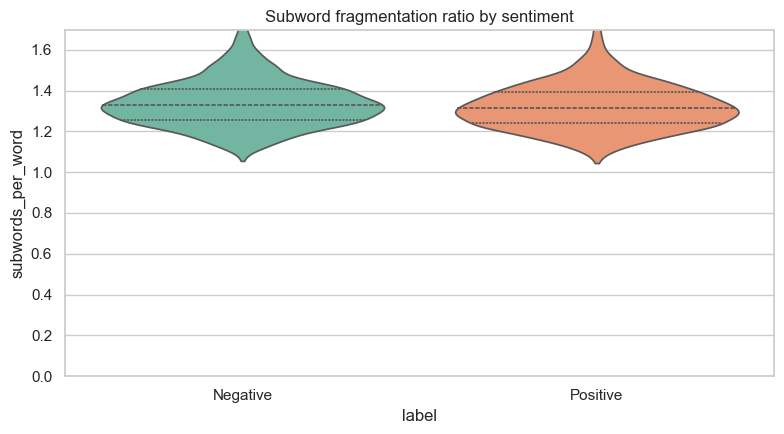

In [6]:
from collections import Counter
word_freq = Counter()
for text in tok_sample.text:
    word_freq.update(w.lower() for w in re.findall(r"[A-Za-z]+(?:'[A-Za-z]+)?", text))
frag_rows = []
for word, freq in word_freq.most_common(3000):
    pieces = tokenizer.tokenize(word)
    if len(pieces) > 1:
        frag_rows.append({'word': word, 'frequency': freq, 'pieces': len(pieces), 'segmentation': ' | '.join(pieces)})
frag_df = pd.DataFrame(frag_rows).sort_values(['frequency','pieces'], ascending=[False,False]).head(15)
display(frag_df)
if len(frag_df):
    plot_df = frag_df.sort_values('pieces')
    plt.figure(figsize=(10,6)); sns.barplot(data=plot_df, x='pieces', y='word', hue='pieces', palette='mako', legend=False)
    plt.title('Frequent words split into multiple BERT subwords'); plt.xlabel('Number of subword pieces'); plt.ylabel('Word'); plt.tight_layout(); plt.show()
else:
    print('No fragmented words found in the inspected frequent-word range.')

# Compare how often each sentiment has a high subword-to-word ratio.
plt.figure(figsize=(8,4.5)); sns.violinplot(data=tok_sample, x='label', y='subwords_per_word', inner='quartile', cut=0, palette='Set2')
plt.xticks([0,1], ['Negative','Positive']); plt.ylim(0, tok_sample.subwords_per_word.quantile(.99)); plt.title('Subword fragmentation ratio by sentiment'); plt.tight_layout(); plt.show()

<!-- codex-analysis-tok-fragmentation -->
### Nhận xét về subword fragmentation

Các từ bị tách thường gặp nhất trong mẫu là contraction. Ví dụ `it's` xuất hiện 3.257 lần và được tách thành `it | ' | s`; `don't` xuất hiện 1.685 lần thành `don | ' | t`; `doesn't` xuất hiện 923 lần thành `doesn | ' | t`. Đây là chia thành subword hợp lệ của vocabulary, không đồng nghĩa từ bị biến thành `[UNK]`. Việc tách dấu nháy thành token riêng làm số subword cao hơn số từ khoảng trắng; vì contraction có mặt thường xuyên trong review, hiệu ứng này không chỉ đến từ từ hiếm.


## 6. Experiment — padding efficiency

So sánh padding động theo batch với padding cố định `max_length=128`. Utilization = số vị trí token thật / tổng vị trí tensor. Batch được gom theo thứ tự cố định từ mẫu để so sánh lặp lại được.

,batch_size,strategy,utilization_pct,padding_pct
0,8,Dynamic padding,96.66,3.34
1,8,Fixed max_length=128,96.66,3.34
2,16,Dynamic padding,96.66,3.34
3,16,Fixed max_length=128,96.66,3.34
4,32,Dynamic padding,96.66,3.34
5,32,Fixed max_length=128,96.66,3.34
6,64,Dynamic padding,96.66,3.34
7,64,Fixed max_length=128,96.66,3.34


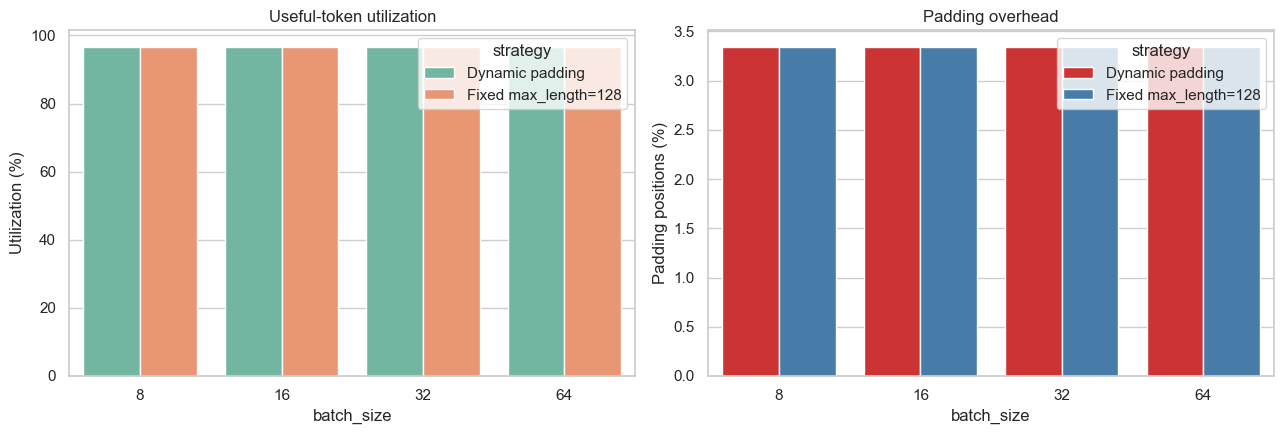

Batch uses truncated sequences (max_length=128); dynamic padding here means pad each batch to its longest sequence.


In [7]:
PAD_SAMPLE_N = min(1200, len(train_df))
pad_texts = train_df.sample(PAD_SAMPLE_N, random_state=SEED).text.tolist()
pad_lengths = [len(tokenizer(text, add_special_tokens=True, truncation=True, max_length=128)['input_ids']) for text in pad_texts]
pad_rows = []
for batch_size in [8, 16, 32, 64]:
    dynamic_slots = fixed_slots = useful_tokens = n_batches = 0
    for start in range(0, len(pad_texts), batch_size):
        batch_lens = pad_lengths[start:start+batch_size]
        if not batch_lens: continue
        n = len(batch_lens); useful_tokens += sum(batch_lens); n_batches += 1
        dynamic_slots += n * max(batch_lens)
        fixed_slots += n * 128
    pad_rows.extend([
        {'batch_size': batch_size, 'strategy': 'Dynamic padding', 'utilization_pct': 100*useful_tokens/dynamic_slots, 'padding_pct': 100*(dynamic_slots-useful_tokens)/dynamic_slots},
        {'batch_size': batch_size, 'strategy': 'Fixed max_length=128', 'utilization_pct': 100*useful_tokens/fixed_slots, 'padding_pct': 100*(fixed_slots-useful_tokens)/fixed_slots},
    ])
pad_df = pd.DataFrame(pad_rows); display(pad_df.round(2))
fig, axes = plt.subplots(1, 2, figsize=(13,4.5))
sns.barplot(data=pad_df, x='batch_size', y='utilization_pct', hue='strategy', ax=axes[0], palette='Set2'); axes[0].set_title('Useful-token utilization'); axes[0].set_ylabel('Utilization (%)')
sns.barplot(data=pad_df, x='batch_size', y='padding_pct', hue='strategy', ax=axes[1], palette='Set1'); axes[1].set_title('Padding overhead'); axes[1].set_ylabel('Padding positions (%)')
plt.tight_layout(); plt.show()
print('Batch uses truncated sequences (max_length=128); dynamic padding here means pad each batch to its longest sequence.')

<!-- codex-analysis-tok-padding -->
### Nhận xét về padding efficiency

Trong mẫu 1.200 review bị truncate ở 128 token, cả batch size 8, 16, 32 và 64 đều cho utilization 96,66% và padding 3,34%; dynamic padding và fixed `max_length=128` cho cùng số liệu. Một giải thích phù hợp với phép đo là gần 90% review vượt 128 token trước khi truncate, nên các batch thường có ít nhất một chuỗi chạm độ dài 128; khi đó dynamic padding vẫn phải pad cả batch tới 128. Vì vậy trong sample này dynamic padding không giảm overhead đo được. Kết quả phụ thuộc thứ tự batch, cách truncate và mẫu 1.200 review; nếu gom các review ngắn theo batch hoặc tăng max length, hiệu quả có thể khác.


## 7. Summary tables and student analysis

### 1. Vì sao số subword khác số từ tách bằng khoảng trắng?

Tokenizer BERT dùng subword nên một từ có thể được giữ thành một token hoặc tách thành nhiều mảnh. Trong bảng fragmentation, `it's` được tách thành `it | ' | s`, còn `don't` thành `don | ' | t`. Vì vậy số subword thường lớn hơn số từ đếm theo khoảng trắng. Trên 5.000 review, trung bình có 231,34 từ nhưng 308,77 subword nội dung; tỷ lệ trung bình là 1,33 subword trên mỗi từ.

### 2. Ý nghĩa của các token và mask

`[CLS]` là token đặc biệt ở đầu chuỗi, cung cấp biểu diễn dùng cho phân loại. `[SEP]` đánh dấu vị trí kết thúc chuỗi. Trong ví dụ, `[CLS]` có token ID 101, `attention_mask = 1` và `special_tokens_mask = 1`.

`attention_mask` bằng 1 ở các vị trí có token thật, gồm cả special token; vị trí padding thường có giá trị 0. `special_tokens_mask` đánh dấu token đặc biệt, chẳng hạn `[CLS]` và `[SEP]`; các token nội dung có giá trị 0. Hai mask phục vụ mục đích khác nhau: một mask cho biết vị trí nào được chú ý, mask còn lại cho biết token nào là token đặc biệt.

### 3. Chọn max length

Tôi chọn max length 256 làm mức cân bằng trong các lựa chọn đã khảo sát. Ở giới hạn 128, 89,68% review bị cắt và trung bình chỉ giữ lại 56,06% số token gốc. Tăng lên 256 giảm tỷ lệ review bị cắt còn 43,80% và giữ trung bình 83,43% token. Dùng 512 giữ được 95,97% token và chỉ 14,40% review bị cắt, nhưng độ dài chuỗi lớn hơn làm chi phí tính toán tăng. Vì vậy 256 giữ được thêm nhiều ngữ cảnh so với 128 mà chưa phải xử lý chuỗi dài như 512.

### 4. Lãng phí padding cố định so với dynamic padding

Trong mẫu 1.200 review với giới hạn 128, cả batch size 8, 16, 32 và 64 đều có utilization 96,66% và padding 3,34% ở cả hai cách padding. Theo kết quả đo này, padding cố định không lãng phí thêm vị trí nào so với dynamic padding: chênh lệch là 0 điểm phần trăm ở cả bốn batch size. Nguyên nhân có thể là các batch thường chứa ít nhất một chuỗi đã chạm giới hạn 128, khiến dynamic padding vẫn phải pad batch đến độ dài 128.

### 5. Độ dài và tỷ lệ subword/word theo sentiment

Hai lớp có độ dài điển hình khá gần nhau. Review negative có trung bình 229,6 từ và median 174 từ; review positive có trung bình 233,1 từ và median 172 từ. Biểu đồ tỷ lệ subword trên từ giữa hai sentiment có phần phân bố chồng lấn, không cho thấy sự tách biệt rõ ràng. Do đó, từ các biểu đồ này tôi chỉ kết luận rằng độ dài và tỷ lệ subword/word trong hai lớp có vẻ tương tự; không thể suy ra độ dài gây ra sentiment hay ngược lại.